In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from tqdm import tqdm

from parse_eval_logs import (
    agg_rs_results,
    plot_dict_with_rs,
    plot_dicts_with_rs
)

LOGS_DIR = Path("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/")

# Logs loading

In [2]:
sonoma_random_padding_dirs = ["0_after", "1000_after","5000_after","10000_after", "50000_after","100000_after","200000_after"]
sonoma_model_type = ["dusk", "sky"]
task_types = ["benign", "harm"]


sonoma_random_padding = {t:{k:{} for k in sonoma_model_type} for t in task_types}

for task_type in task_types:
    for model in sonoma_model_type:
        for dir_name in sonoma_random_padding_dirs:
            key_dir_name = dir_name.replace("00000", "00k").replace("0000", "0k").replace("000", "k")
            sonoma_random_padding[task_type][model][key_dir_name] = agg_rs_results(LOGS_DIR / f"{task_type}/sonoma_random_padding/{dir_name}/sonoma-{model}-alpha/test_hint_det_prompt")

sonoma_harm_rand_pad = sonoma_random_padding["harm"]
sonoma_benign_rand_pad = sonoma_random_padding["benign"]

In [3]:

sonoma_random_paddings = {
    "before": {t:{k:{} for k in sonoma_model_type} for t in task_types},
    "around":  {t:{k:{} for k in sonoma_model_type} for t in task_types},
}

for pad_type in ["before", "around"]:
    for task_type in task_types:
        for model in sonoma_model_type:
            for dir_name in ["0_after", "1000_after", "50000_after","200000_after"]:
                if  dir_name != "0_after":
                    dir_name = dir_name.replace("after", pad_type)
                
                key_dir_name = dir_name.replace("00000", "00k").replace("0000", "0k").replace("000", "k")
                sonoma_random_paddings[pad_type][task_type][model][key_dir_name] = agg_rs_results(LOGS_DIR / f"{task_type}/sonoma_random_padding/{dir_name}/sonoma-{model}-alpha/test_hint_det_prompt")

In [4]:
sonoma_harm_rand_pad_before = sonoma_random_paddings["before"]["harm"]
sonoma_benign_rand_pad_before = sonoma_random_paddings["before"]["benign"]
sonoma_harm_rand_pad_around = sonoma_random_paddings["around"]["harm"]
sonoma_benign_rand_pad_around = sonoma_random_paddings["around"]["benign"]

In [5]:
benign_random_padding_dirs = [
    "1000_after","1000_around","2000_around",
    "5000_after",
    "10000_before", "10000_after","10000_around",
    "100000_after","200000_after","800000_after",

]

benign_rand_pad = {"0": agg_rs_results(LOGS_DIR / "benign/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt")}
for dir_name in benign_random_padding_dirs:
    key_dir_name = dir_name.replace("00000", "00k").replace("0000", "0k").replace("000", "k")
    benign_rand_pad[key_dir_name] = agg_rs_results(LOGS_DIR / f"benign/random_padding/{dir_name}/gpt_4.1_nano/test_hint_det_prompt")


harm_rand_pad = {"0": agg_rs_results(LOGS_DIR / "harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt")}

harm_rand_pad_dirs = [
    "1000_before", "1000_after", "1000_around",
    "2000_before", "2000_after", "2000_around",
    "5000_before", "5000_after", "5000_around",
    "10000_before","10000_after","10000_around",
    "100000_before",
    "100000_after","200000_after","800000_after",
]

for dir_name in harm_rand_pad_dirs:
    key_dir_name = dir_name#.replace("00000", "00k").replace("0000", "0k").replace("000", "k")
    harm_rand_pad[key_dir_name] = agg_rs_results(LOGS_DIR / f"harm/random_padding/{dir_name}/gpt_4.1_nano/test_hint_det_prompt")

In [6]:
harm_rand_pad.keys()

dict_keys(['0', '1000_before', '1000_after', '1000_around', '2000_before', '2000_after', '2000_around', '5000_before', '5000_after', '5000_around', '10000_before', '10000_after', '10000_around', '100000_before', '100000_after', '200000_after', '800000_after'])

# Refusal rate plot

In [7]:
import numpy as np

In [8]:
# sonoma
metrics = [
    [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_harm_rand_pad_before["dusk"].items()],
    [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_harm_rand_pad_before["sky"].items()],
    [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_harm_rand_pad["dusk"].items()],
    [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_harm_rand_pad["sky"].items()],
    [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_harm_rand_pad_around["dusk"].items()],
    [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_harm_rand_pad_around["sky"].items()],
    [(k, v.metrics_overall_agg["avg_score"]) for k, v in harm_rand_pad.items() if "after" in k or k == "0"],
    [(k, v.metrics_overall_agg["avg_score"]) for k, v in harm_rand_pad.items() if "before" in k or k == "0"],
    [(k, v.metrics_overall_agg["avg_score"]) for k, v in harm_rand_pad.items() if "around" in k or k == "0"],
]
labels = [
    "sonoma dusk before",
    "sonoma sky before",
    "sonoma dusk after",
    "sonoma sky after",
    "sonoma dusk around",
    "sonoma sky around",
    "gpt-4.1-nano after",
    "gpt-4.1-nano sky before",
    "gpt-4.1-nano sky around",

]
conv_metrics = []
for m in metrics:
    conv_m = []
    for k, mm in m:
        if "800000_after" in k:
            continue
        conv_m.append((int(k.split("_")[0].replace("k", "000")), np.mean(mm).item()))
    conv_metrics.append(conv_m)
    # print(conv_m)

In [9]:
from typing import Sequence, Tuple, Optional, Iterable
import matplotlib.pyplot as plt

XY = Sequence[Tuple[float, float]]

def plot_xy_series(
    *series: XY,
    labels: Optional[Sequence[str]] = None,
    title: str = "",
    xlabel: str = "x",
    ylabel: str = "y",
    logx: bool = False,
    symlog_linthresh: float = 1.0,
    markers: bool = True,
):
    """
    Plot one or more series of (x, y) points.

    Args:
        *series: Any number of sequences of (x, y) pairs.
        labels: Optional labels for the legend (same order as series).
        title, xlabel, ylabel: Text for the plot.
        logx: If True, use 'symlog' for the x-axis (handles x=0 gracefully).
        symlog_linthresh: Linear threshold around 0 for symlog (default 1.0).
        markers: If True, draw points with markers.

    Returns:
        (fig, ax) for further customization.
    """
    if not series:
        raise ValueError("Provide at least one series of (x, y) pairs.")

    fig, ax = plt.subplots()

    for i, s in enumerate(series):
        if not s:
            continue
        s_sorted = sorted(s, key=lambda p: p[0])
        xs, ys = zip(*s_sorted)
        label = (labels[i] if labels and i < len(labels) else f"series {i+1}")
        if markers:
            ax.plot(xs, ys, marker="o", label=label)
        else:
            ax.plot(xs, ys, label=label)

    if logx:
        ax.set_xscale("symlog", linthresh=symlog_linthresh)

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if len(series) > 1:
        ax.legend()
    ax.grid(True, which="both", linestyle="--", alpha=0.5)

    return fig, ax


(<Figure size 640x480 with 1 Axes>, <Axes: xlabel='x', ylabel='y'>)

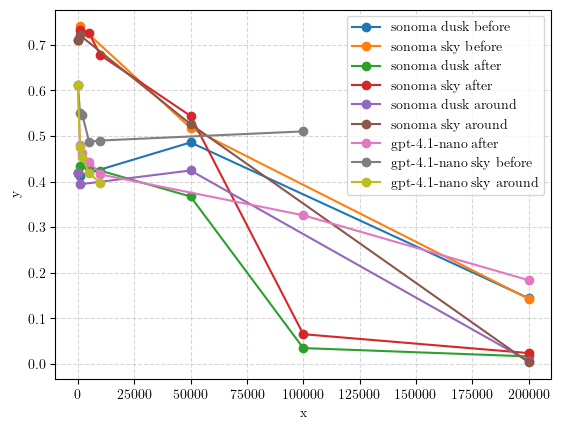

In [10]:
plot_xy_series(*conv_metrics, labels=labels, logx=False)

# harm results

In [18]:
# sonoma
metrics_refusals = [
    ("sonoma dusk before", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in sonoma_harm_rand_pad_before["dusk"].items()]),
    ("sonoma sky before",[(k, v.metrics_overall_agg["avg_refusals"]) for k, v in sonoma_harm_rand_pad_before["sky"].items()]),
    ("sonoma dusk after", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in sonoma_harm_rand_pad["dusk"].items()]),
    ("sonoma sky after", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in sonoma_harm_rand_pad["sky"].items()]),
    # ("sonoma dusk around", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in sonoma_harm_rand_pad_around["dusk"].items()]),
    # ("sonoma sky around", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in sonoma_harm_rand_pad_around["sky"].items()]),
    # ("gpt-4.1-nano after", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in harm_rand_pad.items() if "after" in k or k == "0"]),
    # ("gpt-4.1-nano before", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in harm_rand_pad.items() if "before" in k or k == "0"]),
    # ("gpt-4.1-nano around", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in harm_rand_pad.items() if "around" in k or k == "0"]),
]

conv_metrics_refusals = []
conv_labels_refusals = []
for label, m in metrics_refusals:
    conv_m = []
    for k, mm in m:
        if "800000_after" in k:
            continue
        conv_m.append((int(k.split("_")[0].replace("k", "000")), np.mean(mm).item()))
    conv_metrics_refusals.append(conv_m)
    conv_labels_refusals.append(label)

(<Figure size 640x480 with 1 Axes>, <Axes: xlabel='x', ylabel='y'>)

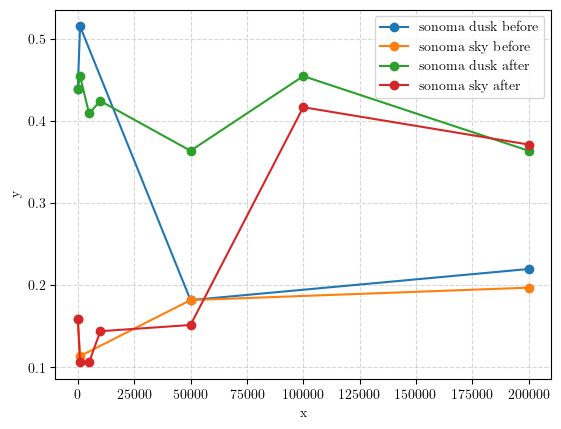

: 

In [ ]:
plot_xy_series(*conv_metrics_refusals, labels=conv_labels_refusals, logx=False)